# Visium HD mouse small intestine — segmentation-free cell-type map (cellman.spatial)

End-to-end **count-platform** pipeline for a 10x **Visium HD** mouse small-intestine sample,
using the `cellman.spatial` **count (blur) backend** — the same path as Stereo-seq.

**Pipeline**
`load_visiumhd → select_gene_panel → compute_vf (blur) → downsample_vector (lookup) →
cluster_vectors → (agentic annotation) → merge → map_celltypes → filter → plot`

**Why this differs from the transcript path (Xenium/MERFISH)**
Visium HD gives a **bin × gene count matrix** (native 2 µm squares), not molecule-resolved
transcripts. So the KDE-equivalent vector field is built by **rasterizing the panel counts
to a grid and Gaussian-blurring** them (`compute_vf`), and `downsample_vector` just *looks up*
sampled voxels in that field (no per-molecule KDE).

## Step 0 — Configuration

In [1]:
from pathlib import Path
import cellman.spatial as cms

ROOT        = "/bce/groups/pnucolab/analysis/l202255179/UNNAMED"
VISIUM_DIR  = f"{ROOT}/cellman_paper/data/visiumhd_enact"                       # 10x outs/ (binned_outputs/)
FULLRES     = f"{VISIUM_DIR}/Visium_HD_Mouse_Small_Intestine_tissue_image.btf"  # brightfield H&E full-res

STORE   = f"{ROOT}/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine"
SDATA   = f"{STORE}/visiumhd_small_intestine.sdata.zarr"   # unified input+output SpatialData
SCRIPTS = f"{ROOT}/CeLLMan/cellman/spatial/scripts"

SPECIES, ORGAN = "mouse", "small_intestine"   # Cell-Ontology wing for the gene panel
ONTO_API   = "http://10.125.208.41:8088"      # KG REST server (dev); or set None → HVG-only
DEVICE     = "cuda:1"                          # NOTE: CUDA 0 = RTX 4090 (opposite of nvidia-smi)
NCORES     = 30

# vector-field geometry
BIN_UM        = 2      # rasterization grid (µm); Visium HD native square = 2 µm
BANDWIDTH_UM  = 2.5      # Gaussian blur bandwidth (µm); segfree sweet spot ≈ 2 µm
SIGMA_BIN     = BANDWIDTH_UM / BIN_UM          # σ in bin units
SAMPLING_DIST = 1.0    # sampling distance (µm)
HVG_N         = 5000

Path(STORE).mkdir(parents=True, exist_ok=True)
print("cellman.spatial", cms.__version__, "| store:", STORE)

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/scanpy/_utils/__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/scanpy/readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.i

cellman.spatial 0.1.0 | store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine


## Step 1 — Load Visium HD → `GridDataset` (unified SpatialData)

`load_visiumhd` reads the `binned_outputs/square_002um` counts + full-res H&E via
`spatialdata_io.visium_hd`, keeps in-tissue bins, converts `obsm['spatial']` to µm, fits the
lattice→pixel affine, and returns a uniform SpatialData (`tables['table']` + `images['staining']`).
Brightfield H&E is tissue-on-light, so `he_revert=True` is set internally.

In [2]:
import spatialdata as sd
if Path(SDATA).exists():
    sdata = sd.read_zarr(SDATA); print("loaded existing sdata:", SDATA)
else:
    sdata = cms.load_visiumhd(VISIUM_DIR, species=SPECIES, organ=ORGAN,
                              bin_um=BIN_UM, fullres_image_file=FULLRES)
    sdata.write(SDATA)   # persist unified input (tables['table'] + images['staining']); one-time
grid = cms.GridDataset.from_sdata(sdata)   # lightweight view for HVG / panel
print("sdata:", dict(tables=list(sdata.tables), images=list(sdata.images)))
print("bins:", grid.raw.n_obs, "| genes:", grid.n_genes,
      "| origin µm:", tuple(round(v, 1) for v in grid.origin))

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/cellman/spatial/_io/_loaders.py:112: FutureWarning: `load_segmentations_only` default value will change to `True` in future releases. Please set it explicitly to `True` or `False` to avoid this warning.
  sdata = spatialdata_io.visium_hd(str(path), bin_size=bin_um,
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/spatialdata/_core/spatialdata.py:170: UserWarning: The table is annotating 'Visium_HD_Mouse_Small_Intestine_square_002um', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: 

sdata: {'tables': ['table'], 'images': ['staining']}
bins: 5479660 | genes: 19059 | origin µm: (262.0, 120.0)


In [3]:
sdata

SpatialData object, with associated Zarr store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine/visiumhd_small_intestine.sdata.zarr
├── Images
│     └── 'staining': DataArray[cyx] (3, 21943, 23618)
└── Tables
      └── 'table': AnnData (5479660, 19059)
with coordinate systems:
    ▸ 'global', with elements:
        staining (Images)

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/spatialdata/_core/spatialdata.py:170: UserWarning: The table is annotating 'Visium_HD_Mouse_Small_Intestine_square_002um', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/spatialdata/_core/spatialdata.py:170: UserWarning: The table is annotating 'Visium_HD_Mouse_Small_Intestine_square_002um', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)


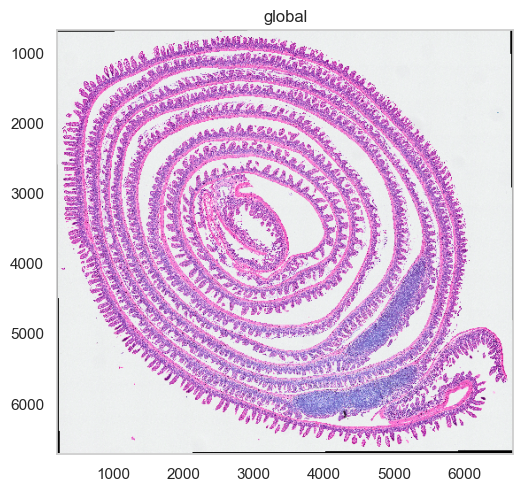

In [4]:
import spatialdata_plot

sdata.pl.render_images('staining').pl.show()

## Step 2 — Gene panel = HVG ∪ Cell-Ontology markers

HVG is estimated directly on the native 2 µm bins (Visium HD is already binned, so no coarse
re-aggregation is needed); ontology markers for `mouse/small_intestine` are unioned in. If the
KG server is unreachable this degrades to HVG-only automatically.

In [5]:
panel, onto_markers = cms.select_gene_panel(
    grid.raw, SPECIES, ORGAN, hvg_n=HVG_N, server_url=ONTO_API)
print("panel genes:", len(panel), "| ontology markers in panel:", len(onto_markers))

[panel] HVG (seurat_v3 on 100000 bins, denylist-filtered): 4996
[panel] slim-index mouse/small_intestine: n_terms=60 version=2026-07-14 → 329 marker genes
[panel] final panel: 5186 genes (HVG 4996 ∪ ontology-in-data 317)
panel genes: 5186 | ontology markers in panel: 317


## Step 3 — `compute_vf` (rasterize + GPU blur)

Aggregates the panel counts to a `BIN_UM` grid and Gaussian-blurs into `vf_normalized`
(bandwidth = `SIGMA_BIN * BIN_UM` µm). Only the normalized field is persisted.

In [6]:
ds = cms.SSAMDataset(STORE)
analysis = cms.SSAMAnalysis(ds, ncores=NCORES, verbose=True)

zarr keys: ['visiumhd_small_intestine.sdata.zarr']


In [8]:
analysis.compute_vf(sdata, bin_um=BIN_UM, panel=panel,
                    sampling_distance=SAMPLING_DIST, sigma_bin=SIGMA_BIN, device=DEVICE)

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=12, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
compute_vf (blur, tiled): 100%|██████████| 52/52 [07:21<00:00,  8.50s/it]

[compute_vf] blur raster (3285, 3191)@2µm → vf (5186, 3285, 3191)@2.0µm (stride 1, compute tile 64×512, store chunk 32×32, radius 6, bandwidth 2.5µm, fp32)


AnnData object with n_obs × n_vars = 5479660 × 5186
    obs: 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'bin_size_um', 'grid_origin_um'
    obsm: 'spatial'

## Step 4 — `downsample_vector` (count lookup)

Samples voxels from the H&E tissue mask and looks them up in the blur field (`grid=` count
path; no KDE). Brightfield H&E is tissue-on-light, so `GridDataset.he_revert=True` inverts
before thresholding.

In [9]:
adata = analysis.downsample_vector(sdata, n_samples_per_block=5, block_um=10,
                                   vf_norm_percentile=25)
adata

downsample_vector (lookup, 6179 tiles, 30w): 100%|██████████| 6179/6179 [00:36<00:00, 169.64it/s]


[downsample] otsu=69.57 mask_px=192249295 sampled=720408 kept(vf_norm>2.393)=655646


AnnData object with n_obs × n_vars = 655646 × 5186
    obs: 'vf_norm'
    obsm: 'spatial'

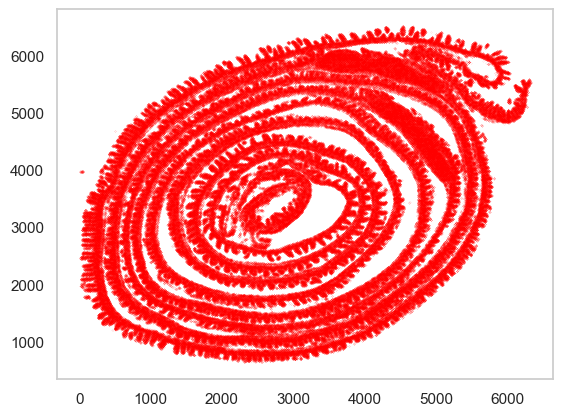

In [10]:
ds.plot_downsampled_vector(s=0.01)

In [2]:
import scanpy as sc
adata = sc.read_h5ad('/bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine/mouse_small_intestine_cls.h5ad')
adata

AnnData object with n_obs × n_vars = 655646 × 5186
    obs: 'vf_norm', 'leiden'
    uns: '__cellman_cluster_raw', 'leiden_colors', 'neighbors', 'pca'
    obsm: 'X_pca', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [3]:
del adata.obs['leiden']
del adata.uns
del adata.obsm['X_pca']
del adata.varm
del adata.obsp

adata

AnnData object with n_obs × n_vars = 655646 × 5186
    obs: 'vf_norm'
    obsm: 'spatial'

In [4]:
adata.write_h5ad(f"{STORE}/mouse_small_intestine_cls.h5ad")

In [5]:
adata

AnnData object with n_obs × n_vars = 655646 × 5186
    obs: 'vf_norm'
    obsm: 'spatial'

In [7]:
STORE

'/bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine'

## Step 6 — Agentic annotation (external step)

Cluster → cell-type identity is assigned by the **annotate-mode-v2** skill (LLM + Cell-Ontology
KG), which runs *outside* this notebook and writes
`annotation_out/ssam_clusters_annotated.h5ad` with `obs['cellman_annotation']`.
Run it against `mouse_small_intestine_cls.h5ad` (mouse / small_intestine wing), then continue below.

/annotate-mode-v2 Annotate the h5ad below using the mouse-small_intestine-expert agent.

- input : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine/mouse_small_intestine_cls.h5ad
- out : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine
- tissue : mouse, small intestine
- virtual env : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv
- note : use 5090 GPU on device '1'

/tmp/ipykernel_229145/4140354767.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(anno, color="cellman_annotation", spot_size=10)


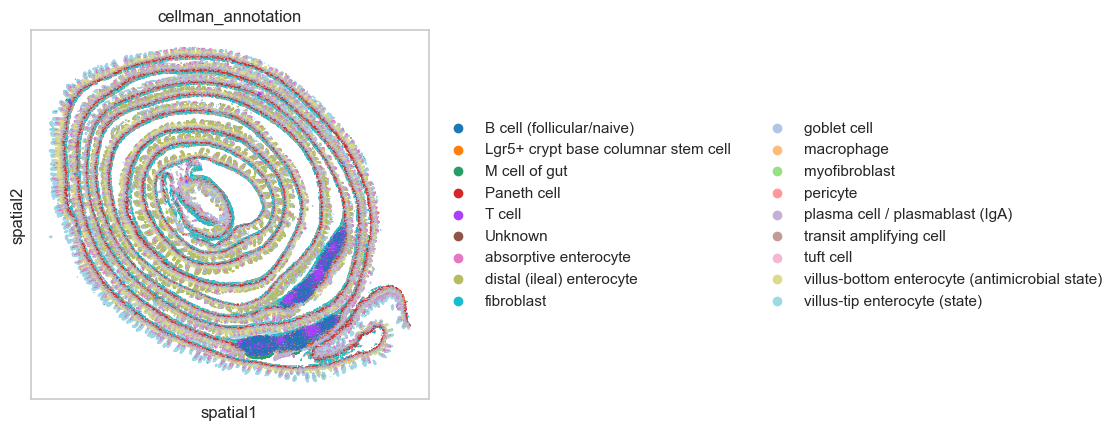

In [2]:
import scanpy as sc

ANNO = f"{STORE}/annotation_out/mouse_small_intestine_cls_annotated.h5ad"
if Path(ANNO).exists():
    anno = sc.read_h5ad(ANNO)
    sc.pl.spatial(anno, color="cellman_annotation", spot_size=10)
else:
    anno = None
    print("annotation not found yet — run annotate-mode to produce:", ANNO)

## Step 7 — Merge annotated clusters → centroids

In [ ]:
import subprocess, sys
subprocess.run([sys.executable, f"{SCRIPTS}/merge_clusters.py",
                "--store-dir", STORE,
                "--annotate-out", f"{STORE}/annotation_out",
                "--legacy"], check=True)

## Step 8 — `map_celltypes` over the blur field

For count data the field is already built, so `map_celltypes` reads it and maps every voxel by
`method`:
- `'corr'` — centroid Pearson (default; matches the transcript path),
- `'tsvm'` — linear/transductive SVM (higher label fidelity),
- `'knn'`  — k-NN vote.

No `sdata` and no GPU KDE — it streams `vf_normalized`.

In [ ]:
import spatialdata as sd
sdata = sd.read_zarr(SDATA)   # reload unified sdata (robust to kernel restart)
analysis.map_celltypes(method="corr", gpu_device=DEVICE)
# alternative: analysis.map_celltypes(method="tsvm", gpu_device=DEVICE)

## Step 9 — Filter + plot the cell-type map

In [ ]:
analysis.filter_celltypemaps(min_r=0)
colors = anno.uns.get('cellman_annotation_colors') if anno is not None else None
# write the map into the SAME sdata: labels + RGB image + annotating table
ds.write_celltype_map(sdata, annotation_csv=f"{STORE}/merged_annotation.csv", colors=colors)
for _el in ("cellman_celltype_map", "cellman_celltype_map_rgb", "cellman_celltype"):
    sdata.write_element(_el, overwrite=True)   # persist outputs into the unified sdata zarr

ds.plot_celltypes_map(show_annotation=True, save_to_spatialdata=False,
                      annotation_csv=f"{STORE}/merged_annotation.csv",
                      colors=colors)